# Regressão espacial da variação do domingo por zona

Continuação de `correlatos_sinal_zona.ipynb`. Lá, as regressões simples (uma variável por vez) deixaram o
**Moran's I do resíduo em 0,43–0,46**: as zonas vizinhas se parecem e nenhuma das variáveis explica isso, então
os intervalos de MQO são otimistas. Este notebook responde com modelos que tratam a dependência espacial, em duas
camadas:

1. **Modelos globais** (`spreg`): MQO com os testes LM, erro espacial (SEM), defasagem espacial (SAR) e Durbin
   espacial (SDM). É a **base inferencial**: um coeficiente por variável, com erro-padrão que já leva em conta
   a autocorrelação.
2. **GWR e MGWR** (`mgwr`): coeficientes que variam no território. O MGWR escolhe uma escala espacial para cada
   variável, e o GWR obriga todas a usar a mesma. É **exploratório**: mostra *onde* as associações são mais
   fortes, não substitui a inferência da camada 1.

**O modelo.** O desfecho é a **variação % do embarque médio de domingo, 2023 → 2024**, por zona. Como o
`Sinal_tarifa_zero` é essa variação menos a do dia útil, o dia útil entra aqui como **variável de controle com
peso estimado**, em vez de ser subtraído com peso 1. A **base de domingo de 2023** também entra como controle,
porque ela está no denominador da própria variação: uma zona de base pequena tem variação grande por
construção, e sem esse controle o tamanho da zona se mistura com qualquer variável que ande junto com ele
(a oferta, por exemplo).

| termo | forma | unidade do coeficiente |
|---|---|---|
| variação % do dia útil, 2023 → 2024 | % | p.p. de domingo por p.p. de dia útil |
| base de domingo 2023 (embarques por dia) | log2 | p.p. por dobra da base |
| renda per capita média | log2 | p.p. por dobra da renda |
| partidas por domingo das linhas que cruzam a zona | milhares | p.p. por +1.000 partidas |
| distância de rede à estação | km | p.p. por +1 km |

O log2 só entra onde a variável é muito assimétrica e o ajuste melhora (base e renda). As partidas ficam lineares
porque o log não muda o resultado delas.

**Entrada.** `outputs/04/base_zona_correlatos.parquet` e `outputs/04/tabelas/lisa_sinal_zona.parquet` (rode antes
`correlatos_sinal_zona.ipynb`). Universo: as 322 zonas de São Paulo acima do p05, sem ponderar por população.
Vizinhança: zonas a até 1 km, borda a borda, linhas padronizadas, a mesma do Moran daquele notebook.

**Como ler.** São associações entre zonas, não efeitos causais, e o coeficiente é em variação **relativa**: onde há
mais embarques, o aumento em passageiros pode ser maior mesmo com variação % menor. Renda, raça e distância ao
trilho andam juntas no território. Tudo fica em `outputs/04/`, nada daqui vai para `docs/`.

## Seção 0 — imports e configuração

In [1]:
import contextlib
import io
import time
import warnings
from pathlib import Path

import esda
import geopandas as gpd
import libpysal
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spreg
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Patch
from mgwr.gwr import GWR, MGWR
from mgwr.sel_bw import Sel_BW

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", module="spreg")   # ComplexWarning do indice de condicao e aviso de tolerancia do otimizador do ML

COD_MUNI_SP = 36
SHP_ZONAS = Path("../Dados/pacote-anexos-od_10-02-25_0/002_Site Metro Mapas/Shape/Zonas_2023.shp")
DIST_VIZINHANCA_M = 1000   # a mesma de correlatos_sinal_zona.ipynb: zonas a ate 1 km, borda a borda
SEED = 1
PERM_MORAN = 999
MIN_BW_MGWR = 40           # menor escala do MGWR (em zonas vizinhas): evita coeficiente local quase sem suavizacao
BW_GLOBAL = 0.9            # escala acima de 90% das zonas = efeito tratado como global
INF_BW = 1e10              # largura "infinita" do GWR gaussiano = MQO, para comparar o AICc na mesma escala

DIR_OUT = Path("../outputs/04")
DIR_FIG = DIR_OUT / "figuras"
DIR_TAB = DIR_OUT / "tabelas"
for d in (DIR_FIG, DIR_TAB):
    d.mkdir(parents=True, exist_ok=True)
SALVAR_FIG = dict(dpi=150, bbox_inches="tight", facecolor="white")

Y = "PctDiff_domingo"            # variacao % do embarque medio de domingo, 2023 -> 2024
Y_ROTULO = "Variação % do domingo (2023 → 2024)"
Y_SINAL = "Sinal_tarifa_zero"    # so para conferir o Moran global gravado pelo notebook de correlatos
COR_TEXTO, COR_GRADE, COR_BORDA, COR_FORA = "#262626", "#e3e3e3", "#b3b3b3", "#8c8c8c"
COR_NS = "#bdbdbd"        # zona sem coeficiente local significativo
# Divergente: azul (negativo) <-> cinza neutro <-> vermelho (positivo); o mesmo par de matizes do LISA
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#256abf", "#f0efec", "#d8403f"])

# Termos do modelo. "log" = o ajuste e feito em log2 (coeficiente por dobra); senao x / esc.
VARS = {
    "PctDiff_util":         dict(rot="Variação % do dia útil (controle)", log=False, esc=1, unid="p.p. por p.p."),
    "dia_domingo_2023":     dict(rot="Base de domingo 2023 (log2)", log=True, unid="p.p. por dobra"),
    "renda_pc_media":       dict(rot="Renda per capita (log2)", log=True, unid="p.p. por dobra"),
    "partidas_dom_2023":    dict(rot="Partidas por domingo (mil)", log=False, esc=1000, unid="p.p. por +1.000 partidas"),
    "dist_estacao_rede_km": dict(rot="Distância de rede à estação (km)", log=False, esc=1, unid="p.p. por +1 km"),
}
COLUNAS = list(VARS)
ROT = {c: v["rot"] for c, v in VARS.items()}
ORDEM_CLUSTER = ["Alto-alto", "Baixo-baixo", "Alto-baixo", "Baixo-alto", "Não significativo"]


def fmt_br(x, casas=2):
    # 1234.5 -> "1.234,50"
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

## Seção 1 — base e vizinhança

A base é a de `correlatos_sinal_zona.ipynb`, sem refazer nada. A matriz de vizinhança é reconstruída com o
mesmo critério daquele notebook, e a célula confere que ela devolve o **mesmo Moran's I global do sinal**
que ele gravou. As coordenadas do GWR/MGWR são os centroides das zonas.

In [2]:
base = pd.read_parquet(DIR_OUT / "base_zona_correlatos.parquet")
zonas = gpd.read_file(SHP_ZONAS)[["NumeroZona", "NomeZona", "NumeroMuni", "geometry"]]
zonas = zonas[zonas["NumeroMuni"] == COD_MUNI_SP].drop(columns="NumeroMuni").reset_index(drop=True)
assert zonas.crs.is_projected, "a distancia entre zonas precisa de CRS projetado (metros)"

zon_a = zonas.set_index("NumeroZona").loc[base["NumeroZona"]].reset_index()
assert (zon_a["NumeroZona"].to_numpy() == base["NumeroZona"].to_numpy()).all()
n = len(base)
y = base[Y].to_numpy()
cent = zon_a.geometry.centroid
coords = np.column_stack([cent.x, cent.y])

viz = gpd.sjoin(zon_a[["geometry"]], zon_a[["geometry"]], predicate="dwithin", distance=DIST_VIZINHANCA_M)
viz = viz[viz.index != viz["index_right"]]
B = np.zeros((n, n))
B[viz.index.values, viz["index_right"].values] = 1
assert (B.sum(1) > 0).all(), "zona sem vizinha"
w = libpysal.weights.full2W(B)
w.transform = "r"

# confere com o que o notebook de correlatos gravou (Moran global do sinal)
I_sinal = esda.Moran(base[Y_SINAL].to_numpy(), w, permutations=0).I
I_gravado = pd.read_parquet(DIR_TAB / "moran_sinal_zona.parquet")["moran_i"].iloc[0]
assert abs(I_sinal - I_gravado) < 1e-6, f"Moran global do sinal {I_sinal:.6f} x gravado {I_gravado:.6f}"
print(f"n = {n} zonas | vizinhas por zona: mediana {np.median(B.sum(1)):.0f}, min {int(B.sum(1).min())}, max {int(B.sum(1).max())}")
print(f"Moran's I global do sinal = {I_sinal:.3f} (confere com o notebook de correlatos)")
np.random.seed(SEED)
mY = esda.Moran(y, w, permutations=PERM_MORAN)
print(f"Moran's I global de {Y_ROTULO.lower()} = {mY.I:.3f} (p pseudo = {mY.p_sim:.3f})")
print(f"{Y_ROTULO}: média {y.mean():.1f} p.p., desvio-padrão {y.std():.1f} p.p., de {y.min():.1f} a {y.max():.1f}")


def desenho(cols=COLUNAS):
    # as colunas na escala em que a variavel entra no modelo: log2, ou x / esc
    return pd.DataFrame({c: np.log2(base[c]) if VARS[c]["log"] else base[c] / VARS[c]["esc"] for c in cols})


def moran_residuo(e):
    np.random.seed(SEED)
    m = esda.Moran(np.asarray(e).ravel(), w, permutations=PERM_MORAN)
    return m.I, m.p_sim


def silencia(f, *a, **k):
    # o spreg imprime o nome do modelo a cada ajuste
    with contextlib.redirect_stdout(io.StringIO()):
        return f(*a, **k)


assert desenho().notna().all().all(), "variavel com zona sem valor"

n = 322 zonas | vizinhas por zona: mediana 10, min 1, max 22
Moran's I global do sinal = 0.453 (confere com o notebook de correlatos)
Moran's I global de variação % do domingo (2023 → 2024) = 0.417 (p pseudo = 0.001)
Variação % do domingo (2023 → 2024): média 33.2 p.p., desvio-padrão 14.9 p.p., de -22.7 a 88.1


## Seção 2 — modelos globais: MQO, erro, defasagem e Durbin

Sobre o MQO rodam os testes do multiplicador de Lagrange (LM) para defasagem e para erro espacial, e as versões
**robustas** de cada um. A regra de Anselin: se só um dos robustos é significativo, é o modelo dele; se os dois
são, o critério é o maior, e o AIC ajuda a decidir. Os quatro modelos:

| modelo | o que supõe |
|---|---|
| MQO | nenhuma dependência espacial |
| **SEM** (erro) | a dependência está no erro: algo espacial que falta no modelo; as inclinações continuam lidas como no MQO |
| **SAR** (defasagem) | a variação de uma zona depende da das vizinhas; o coeficiente de cada variável deixa de ser o efeito marginal |
| **SDM** (Durbin) | SAR mais a defasagem das variáveis explicativas; inclui SEM e SAR como casos particulares |

Para comparar, a tabela traz o AIC (todos pela verossimilhança, na mesma escala), o R² (pseudo-R² nos modelos
espaciais) e o **Moran's I do resíduo filtrado**, que diz se o modelo deu conta da dependência.

In [3]:
def coef_tabela(m, tipo, modelo):
    pares = m.t_stat if tipo == "ols" else m.z_stat
    idx = list(m.name_x)
    if len(idx) < len(m.betas):                      # SEM/SAR acrescentam lambda/rho como ultimo parametro
        idx.append("lambda" if modelo.startswith("Erro") else "rho")
    t = pd.DataFrame({"coef": np.asarray(m.betas).ravel(), "p": [q[1] for q in pares]}, index=idx)
    t.index.name = "termo"
    return t.reset_index().assign(modelo=modelo)


def ajusta_globais():
    nomes = [ROT[c] for c in COLUNAS]
    Xv, yv = desenho().to_numpy(), y.reshape(-1, 1)
    ols = silencia(spreg.OLS, yv, Xv, w=w, spat_diag=True, moran=True, name_x=nomes, name_y=Y)
    sem = silencia(spreg.ML_Error, yv, Xv, w=w, name_x=nomes, name_y=Y)
    sar = silencia(spreg.ML_Lag, yv, Xv, w=w, name_x=nomes, name_y=Y)
    sdm = silencia(spreg.ML_Lag, yv, Xv, w=w, slx_lags=1, name_x=nomes, name_y=Y)
    modelos = {
        "MQO": (ols, "ols", ols.u, ols.r2, np.nan),
        "Erro espacial (SEM)": (sem, "ml", sem.e_filtered, sem.pr2, sem.lam),
        "Defasagem (SAR)": (sar, "ml", sar.u, sar.pr2, sar.rho),
        "Durbin espacial (SDM)": (sdm, "ml", sdm.u, sdm.pr2, sdm.rho),
    }
    comp, coefs = [], []
    for nome, (m, tipo, resid, r2, par) in modelos.items():
        I_r, p_r = moran_residuo(resid)
        comp.append(dict(modelo=nome, aic=m.aic, r2=r2, param_espacial=par, moran_residuo=I_r, moran_p=p_r))
        coefs.append(coef_tabela(m, tipo, nome))
    lm = pd.DataFrame({"estatistica": [ols.lm_lag[0], ols.lm_error[0], ols.rlm_lag[0], ols.rlm_error[0]],
                       "p": [ols.lm_lag[1], ols.lm_error[1], ols.rlm_lag[1], ols.rlm_error[1]]},
                      index=["LM defasagem", "LM erro", "LM robusto defasagem", "LM robusto erro"]).rename_axis("teste")
    return dict(comp=pd.DataFrame(comp), coef=pd.concat(coefs, ignore_index=True), lm=lm)


globais = ajusta_globais()
print(f"Termos: {', '.join(ROT[c] for c in COLUNAS)}\n")
print("Testes LM sobre o MQO:")
print(globais["lm"].round(4).to_string())
print("\nComparação dos modelos:")
print(globais["comp"].set_index("modelo").round(3).to_string())

termos_ord = ["CONSTANT"] + [ROT[c] for c in COLUNAS]
coef_larga = globais["coef"].pivot(index="termo", columns="modelo", values="coef")
p_larga = globais["coef"].pivot(index="termo", columns="modelo", values="p")
ordem = termos_ord + [t for t in coef_larga.index if t not in termos_ord]
mostra = pd.concat({"coeficiente": coef_larga.loc[ordem], "p": p_larga.loc[ordem]}, axis=1)
print("\nCoeficientes (p.p. da variação % do domingo) e p-valores:")
print(mostra.round(3).to_string())
print("\nNo SAR e no SDM o coeficiente de uma variável não é o efeito marginal (há o multiplicador 1/(1-rho)); a leitura direta das inclinações vale para MQO e SEM.")

def fmt_p(p):
    return "< 0,001" if p < 0.001 else f"{p:.3f}".replace(".", ",")


# tabela enxuta para o site: coeficiente e p de cada termo em MQO, erro e defasagem (p ja formatado)
pub = pd.DataFrame({"unidade": [VARS[c]["unid"] for c in COLUNAS]}, index=[ROT[c] for c in COLUNAS])
for chave, modelo in [("mqo", "MQO"), ("sem", "Erro espacial (SEM)"), ("sar", "Defasagem (SAR)")]:
    pub[chave] = coef_larga.loc[pub.index, modelo]
    pub[f"p_{chave}"] = p_larga.loc[pub.index, modelo].map(fmt_p)
pub.index.name = "termo"
pub.to_parquet(DIR_TAB / "regressao_espacial_publicada.parquet")

globais["comp"].to_parquet(DIR_TAB / "regressao_espacial_modelos.parquet", index=False)
globais["coef"].to_parquet(DIR_TAB / "regressao_espacial_coef.parquet", index=False)
globais["lm"].to_parquet(DIR_TAB / "regressao_espacial_lm.parquet")

Termos: Variação % do dia útil (controle), Base de domingo 2023 (log2), Renda per capita (log2), Partidas por domingo (mil), Distância de rede à estação (km)

Testes LM sobre o MQO:
                      estatistica       p
teste                                    
LM defasagem             174.2946  0.0000
LM erro                  142.3168  0.0000
LM robusto defasagem      38.0583  0.0000
LM robusto erro            6.0804  0.0137

Comparação dos modelos:
                            aic     r2  param_espacial  moran_residuo  moran_p
modelo                                                                        
MQO                    2472.941  0.450             NaN          0.316    0.001
Erro espacial (SEM)    2369.873  0.409           0.751         -0.011    0.389
Defasagem (SAR)        2364.610  0.633           0.635         -0.002    0.468
Durbin espacial (SDM)  2368.131  0.641           0.639         -0.015    0.344

Coeficientes (p.p. da variação % do domingo) e p-valores:
        

## Seção 3 — GWR e MGWR

**GWR.** Uma regressão ponderada em cada zona, usando as vizinhas mais próximas (núcleo bisquare adaptativo): o
coeficiente passa a variar no mapa. A escala (quantas vizinhas) é **uma só** para todas as variáveis.

**MGWR.** A mesma ideia com **uma escala por variável**. Uma variável cujo efeito é parecido na cidade toda
ganha uma escala quase global; uma cuja associação muda de região ganha uma escala local. Por isso o MGWR
costuma vencer o GWR com menos parâmetros efetivos.

**Detalhes de método.**
- Variáveis e desfecho são **padronizados** para a busca da escala (AICc, adaptativa). Os coeficientes locais são
  convertidos de volta para a unidade original (p.p. da variação do domingo por unidade do termo, como na
  Seção 2). O intercepto local fica em p.p. **em relação à média**, com as variáveis na média.
- `MIN_BW_MGWR` impõe uma escala mínima, para que um coeficiente não seja estimado com poucas zonas.
- A significância local usa o **critério com correção para testes múltiplos do `mgwr`** (`filter_tvals`), que é
  conservador porque cada zona é um teste. Os coeficientes locais não são independentes entre si: leia o mapa
  pelas regiões, não por zona.
- O ganho de ajuste do GWR/MGWR **não é só das variáveis**: um mapa de tendência espacial sozinho já explica
  muito. Por isso entram dois comparadores, o MQO na mesma escala e o **GWR só com o intercepto local**, sem
  nenhuma variável. O que as variáveis acrescentam é a diferença para esse segundo.

In [4]:
def ajusta_gwr():
    nomes = [ROT[c] for c in COLUNAS]
    X = desenho()
    sx = X.std().to_numpy()
    sy = y.std(ddof=1)
    Z = ((X - X.mean()) / X.std()).to_numpy()
    zy = ((y - y.mean()) / y.std()).reshape(-1, 1)
    t0 = time.time()

    bw_g = Sel_BW(coords, zy, Z, kernel="bisquare", fixed=False).search(criterion="AICc")
    gwr = GWR(coords, zy, Z, bw_g, kernel="bisquare", fixed=False).fit()

    sel = Sel_BW(coords, zy, Z, multi=True, kernel="bisquare", fixed=False)
    bws = sel.search(multi_bw_min=[MIN_BW_MGWR], criterion="AICc")
    mg = MGWR(coords, zy, Z, sel, kernel="bisquare", fixed=False).fit()

    # comparadores: MQO na mesma escala (largura infinita) e so o intercepto local
    mqo = GWR(coords, zy, Z, INF_BW, kernel="gaussian", fixed=True).fit()
    bw0 = Sel_BW(coords, zy, np.zeros((n, 0)), kernel="bisquare", fixed=False, constant=True).search(criterion="AICc")
    g0 = GWR(coords, zy, np.zeros((n, 0)), bw0, kernel="bisquare", fixed=False, constant=True).fit()

    sig = mg.filter_tvals() != 0
    locais = pd.DataFrame({"NumeroZona": base["NumeroZona"].to_numpy(), "intercepto": mg.params[:, 0] * sy})
    locais["sig_intercepto"] = sig[:, 0]
    for j, c in enumerate(COLUNAS):
        locais[c] = mg.params[:, j + 1] * sy / sx[j]
        locais[f"sig_{c}"] = sig[:, j + 1]

    comp = pd.DataFrame([
        dict(modelo="MQO (mesma escala)", aicc=mqo.aicc, r2=mqo.R2, enp=mqo.ENP, bw=np.nan, moran_residuo=moran_residuo(mqo.resid_response)[0]),
        dict(modelo="GWR só com intercepto local", aicc=g0.aicc, r2=g0.R2, enp=g0.ENP, bw=bw0, moran_residuo=moran_residuo(g0.resid_response)[0]),
        dict(modelo="GWR", aicc=gwr.aicc, r2=gwr.R2, enp=gwr.ENP, bw=bw_g, moran_residuo=moran_residuo(gwr.resid_response)[0]),
        dict(modelo="MGWR", aicc=mg.aicc, r2=mg.R2, enp=mg.ENP, bw=np.nan, moran_residuo=moran_residuo(mg.resid_response)[0]),
    ])
    escalas = pd.DataFrame({"termo": ["Intercepto"] + nomes, "bw": bws, "pct_zonas": np.asarray(bws) / n})
    return dict(locais=locais, comp=comp, escalas=escalas, segundos=time.time() - t0)


a = ajusta_gwr()
print(f"Ajuste em {a['segundos']:.0f}s\n")
print(a["comp"].set_index("modelo").round(3).to_string())
print("\nEscala espacial de cada termo no MGWR (vizinhas, de 322):")
print(a["escalas"].set_index("termo").round(2).to_string())
a["comp"].to_parquet(DIR_TAB / "mgwr_comparacao.parquet", index=False)
a["escalas"].assign(escala_pct=100 * a["escalas"]["pct_zonas"]).to_parquet(DIR_TAB / "mgwr_escalas.parquet", index=False)

Ajuste em 80s

                                aicc     r2     enp    bw  moran_residuo
modelo                                                                  
MQO (mesma escala)           735.826  0.450   6.000   NaN          0.316
GWR só com intercepto local  756.913  0.472  21.681  44.0          0.026
GWR                          647.499  0.719  57.298  78.0          0.048
MGWR                         607.872  0.721  44.030   NaN         -0.022

Escala espacial de cada termo no MGWR (vizinhas, de 322):
                                      bw  pct_zonas
termo                                              
Intercepto                          48.0       0.15
Variação % do dia útil (controle)  132.0       0.41
Base de domingo 2023 (log2)        320.0       0.99
Renda per capita (log2)             71.0       0.22
Partidas por domingo (mil)         320.0       0.99
Distância de rede à estação (km)    62.0       0.19


### Coeficientes locais: resumo e mapas

Cada painel mostra o coeficiente local de um termo. As zonas em **cinza** não têm coeficiente local significativo
(critério corrigido); as **hachuradas** ficam fora da análise (sem demanda ou base pequena). Termos com escala
quase global (acima de 90% das zonas) não ganham mapa: o coeficiente é praticamente o mesmo em todo lugar, e
aparece no rodapé. O resumo por cluster do LISA liga este notebook ao mapa de aglomerados do **sinal**, do notebook
anterior.

Coeficiente local: mediana de todas as zonas e % de zonas com coeficiente significativo (negativo / positivo)
                                   mediana  pct_sig  pct_sig_neg  pct_sig_pos
termo                                                                        
Intercepto (p.p. vs média)           -0.96     0.08         0.06         0.02
Variação % do dia útil (controle)     1.00     0.98         0.00         0.98
Base de domingo 2023 (log2)          -3.26     1.00         1.00         0.00
Renda per capita (log2)              -7.43     0.76         0.76         0.00
Partidas por domingo (mil)            0.10     0.00         0.00         0.00
Distância de rede à estação (km)     -1.65     0.28         0.28         0.00

Média do coeficiente local por cluster do LISA do sinal:
termo              Base de domingo 2023 (log2)  Distância de rede à estação (km)  Intercepto (p.p. vs média)  Partidas por domingo (mil)  Renda per capita (log2)  Variação % do dia útil (controle)
cluster    

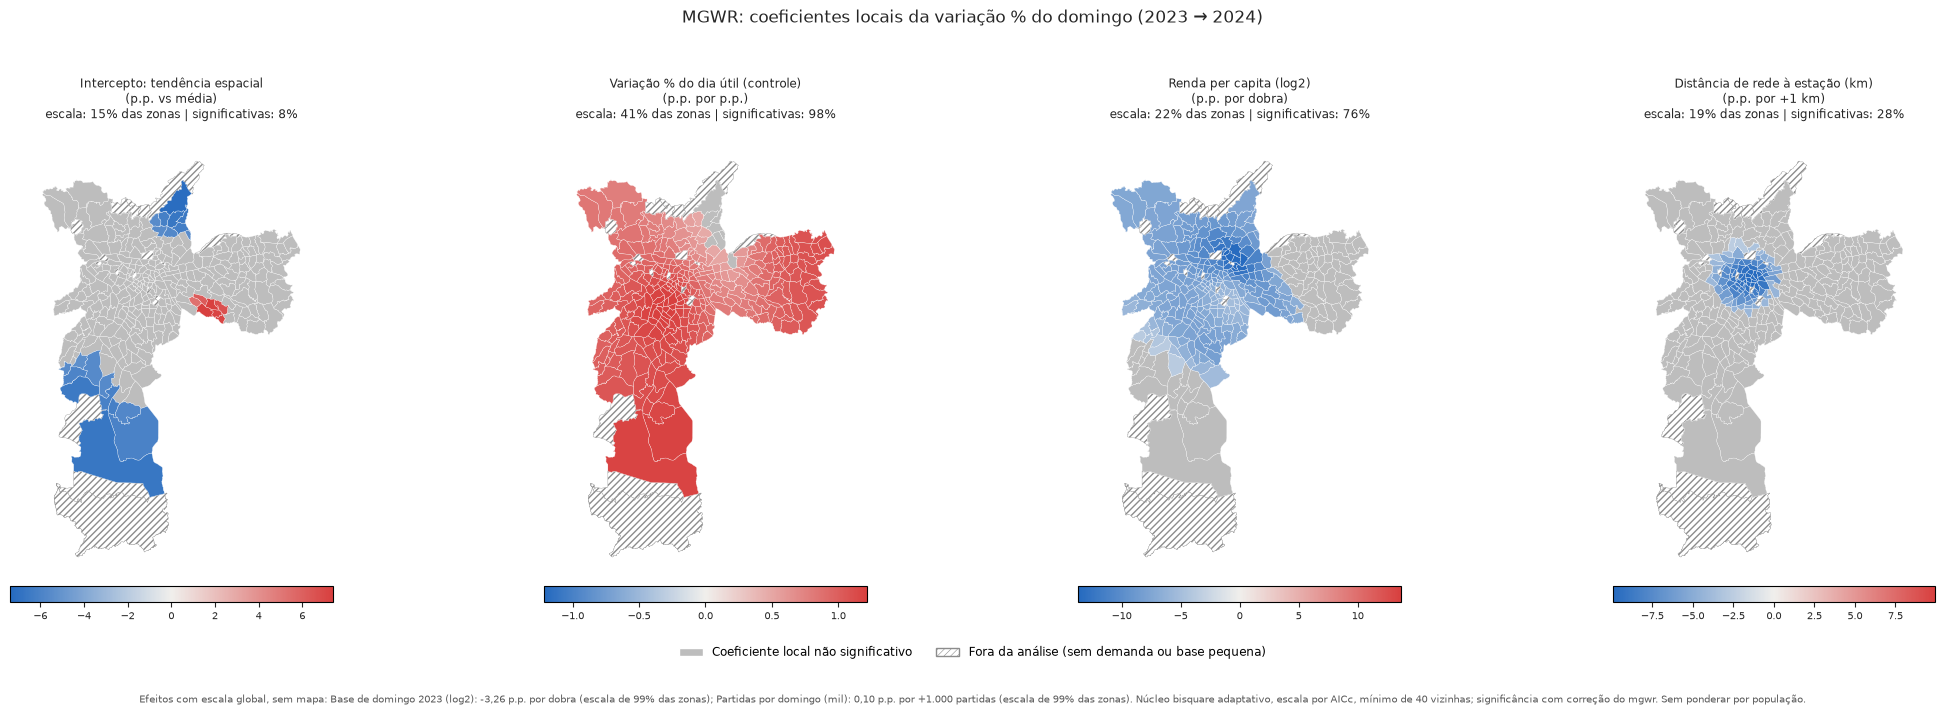

In [5]:
def resumo_locais(res):
    L = res["locais"].merge(pd.read_parquet(DIR_TAB / "lisa_sinal_zona.parquet")[["NumeroZona", "cluster"]], on="NumeroZona")
    linhas = []
    for c, rot in [("intercepto", "Intercepto (p.p. vs média)")] + [(c, ROT[c]) for c in COLUNAS]:
        for cl in ["Todas"] + ORDEM_CLUSTER:
            d = L if cl == "Todas" else L[L["cluster"] == cl]
            linhas.append(dict(termo=rot, cluster=cl, n=len(d), media=d[c].mean(), mediana=d[c].median(),
                               pct_sig=d[f"sig_{c}"].mean(), pct_sig_neg=(d[f"sig_{c}"] & (d[c] < 0)).mean(),
                               pct_sig_pos=(d[f"sig_{c}"] & (d[c] > 0)).mean()))
    return L, pd.DataFrame(linhas)


L, res_cl = resumo_locais(a)
res_cl.to_parquet(DIR_TAB / "mgwr_resumo_cluster.parquet", index=False)
a["locais"].to_parquet(DIR_TAB / "mgwr_coef_locais.parquet", index=False)

print("Coeficiente local: mediana de todas as zonas e % de zonas com coeficiente significativo (negativo / positivo)")
print(res_cl[res_cl["cluster"] == "Todas"].drop(columns=["cluster", "n", "media"]).set_index("termo").round(2).to_string())
print("\nMédia do coeficiente local por cluster do LISA do sinal:")
print(res_cl.pivot(index="cluster", columns="termo", values="media").reindex(["Todas"] + ORDEM_CLUSTER).round(2).to_string())

# --- mapas ---
ESC = {r["termo"]: r["pct_zonas"] for _, r in a["escalas"].iterrows()}
locais_painel = [("intercepto", "Intercepto: tendência espacial\n(p.p. vs média)", ESC["Intercepto"])] + \
                [(c, f"{ROT[c]}\n({VARS[c]['unid']})", ESC[ROT[c]]) for c in COLUNAS if ESC[ROT[c]] < BW_GLOBAL]
globais_txt = [f"{ROT[c]}: {fmt_br(a['locais'][c].median(), 2)} {VARS[c]['unid']} (escala de {ESC[ROT[c]]:.0%} das zonas)"
               for c in COLUNAS if ESC[ROT[c]] >= BW_GLOBAL]

zonas_map = zonas[["NumeroZona", "geometry"]].merge(a["locais"], on="NumeroZona", how="left")
fig, axes = plt.subplots(1, len(locais_painel), figsize=(5.4 * len(locais_painel), 6.6), squeeze=False)
for ax, (c, titulo, esc_rel) in zip(axes.ravel(), locais_painel):
    d = zonas_map[zonas_map[c].notna()]
    ok = d[f"sig_{c}"].astype(bool)
    lim = np.nanpercentile(np.abs(d.loc[ok, c]), 98) if ok.any() else np.nanmax(np.abs(d[c]))
    norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
    zonas_map[zonas_map[c].isna()].plot(facecolor="white", edgecolor=COR_FORA, linewidth=.25, hatch="/////", ax=ax)
    d[~ok].plot(color=COR_NS, edgecolor="white", linewidth=.2, ax=ax)
    if ok.any():
        d[ok].plot(column=c, cmap=CMAP_DIV, norm=norm, edgecolor="white", linewidth=.2, ax=ax)
    sm = plt.cm.ScalarMappable(cmap=CMAP_DIV, norm=norm)
    cb = fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=.035, pad=.02)
    cb.ax.tick_params(labelsize=7, colors=COR_TEXTO)
    ax.set_title(f"{titulo}\nescala: {esc_rel:.0%} das zonas | significativas: {ok.mean():.0%}", fontsize=8.5, color=COR_TEXTO)
    ax.set_axis_off()
with plt.rc_context({"hatch.linewidth": .4}):
    chaves = [Patch(fc=COR_NS, ec="white", label="Coeficiente local não significativo"),
              Patch(fc="white", ec=COR_FORA, hatch="/////", label="Fora da análise (sem demanda ou base pequena)")]
    fig.legend(handles=chaves, loc="lower center", ncol=2, frameon=False, fontsize=8.5, bbox_to_anchor=(.5, -.02))
fig.suptitle(f"MGWR: coeficientes locais da {Y_ROTULO.lower()}", fontsize=12, color=COR_TEXTO)
rodape = ("Efeitos com escala global, sem mapa: " + "; ".join(globais_txt) + ". ") if globais_txt else ""
fig.text(.5, -.07, rodape + f"Núcleo bisquare adaptativo, escala por AICc, mínimo de {MIN_BW_MGWR} vizinhas; significância com correção do mgwr. Sem ponderar por população.",
         ha="center", fontsize=7.5, color="#595959", wrap=True)
fig.tight_layout(rect=(0, .03, 1, .95))
fig.savefig(DIR_FIG / "mgwr_coef_locais.png", **SALVAR_FIG)
plt.show()

## Seção 4 — o que foi gravado

In [6]:
print("Artefatos desta análise em outputs/04/:")
for p in sorted(DIR_OUT.rglob("*")):
    if p.is_file() and (p.name.startswith(("regressao_espacial", "mgwr_"))):
        print(f"  {p.relative_to(DIR_OUT)}")

Artefatos desta análise em outputs/04/:
  figuras\mgwr_coef_locais.png
  tabelas\mgwr_coef_locais.parquet
  tabelas\mgwr_comparacao.parquet
  tabelas\mgwr_escalas.parquet
  tabelas\mgwr_resumo_cluster.parquet
  tabelas\regressao_espacial_coef.parquet
  tabelas\regressao_espacial_lm.parquet
  tabelas\regressao_espacial_modelos.parquet
  tabelas\regressao_espacial_publicada.parquet
